# CIS 443-01 - Analytics Programming
## Program 4
__Worth__: 100 pts.<br />
__Purpose__: Use a SKLearn to build an analytic model for categorical data

### Directions
In the code cell below, write Python code to accomplish the following using what you've learned through the semester. 


#### Part 1

Your code should use the preloaded data set to build a logistic regression model. Perform a training and testing split of this data before you create this model./ 

Once you have created this model, obtain all coefficients created by the model. 

Explain each of the two sets of coefficients, and what they mean. 

Score your model against the testing dataset, and explain when the score returned represents. 

#### Part 2

Use pandas and Matplotlib to create a confusion matrix of the scoring of your model. Because this is a Yes/No Questionaire, you can consider it a TP/TN/FP/FN matrix.



Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Data types:
Age                int64
EstimatedSalary    int64
Purchased          int64
dtype: object

Purchase categories:
[0 1]
Model Accuracy: 80.00%


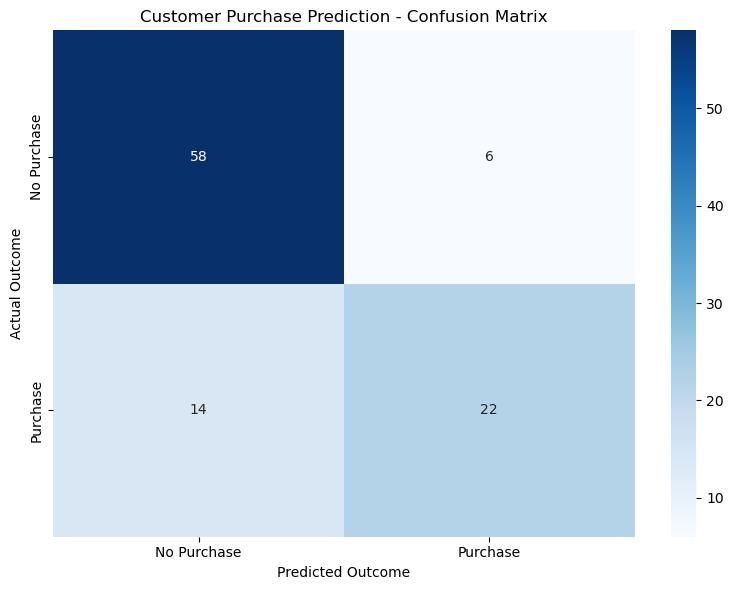


--- Model Coefficients ---
Age: 2.376297
EstimatedSalary: 1.206682
Intercept: -1.1530


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

# Load dataset
ads = pd.read_csv("social_ads.csv")

# Convert Age and Salary to numeric values
ads['Age'] = pd.to_numeric(ads['Age'], errors='coerce')

ads['EstimatedSalary'] = pd.to_numeric(
    ads['EstimatedSalary'].astype(str).str.replace(
        r'[$,]', '', regex=True
    ),
    errors='coerce'
)

# Standardize Purchased values to 0 and 1
ads['Purchased'] = (
    ads['Purchased']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        '0': 0,
        '1': 1,
        'yes': 1,
        'no': 0,
        'true': 1,
        'false': 0
    })
)

# Check for invalid or missing values
print(ads[['Age', 'EstimatedSalary', 'Purchased']].isna().sum())

# Remove incomplete records
ads = ads.dropna(
    subset=['Age', 'EstimatedSalary', 'Purchased']
)

ads['Purchased'] = ads['Purchased'].astype(int)

# Define model variables
x_data = ads[['Age', 'EstimatedSalary']]
y_target = ads['Purchased']

print("\nData types:")
print(ads.dtypes)

print("\nPurchase categories:")
print(ads['Purchased'].unique())


# Split the data
x_train, x_test, y_train, y_test = train_test_split(
    x_data, y_target, test_size=0.25,
    random_state=11, stratify=y_target
)

# Standardize the features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Train the logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaled, y_train)

# Generate predictions
predicted = model.predict(x_test_scaled)

# Calculate model accuracy
accuracy = accuracy_score(y_test, predicted)

print(f"Model Accuracy: {accuracy:.2%}")

# Generate confusion matrix
confusion = confusion_matrix(
    y_test, predicted, labels=[0, 1]
)

# Create visualization
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Customer Purchase Prediction - Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# Model coefficient analysis
print("\n--- Model Coefficients ---")

for name, coefficient in zip(x_data.columns, model.coef_[0]):
    print(f"{name}: {coefficient:.6f}")

print(f"Intercept: {model.intercept_[0]:.4f}")

Be sure to save and exit your Jupyter Notebook and Shutdown Jupyter Lab (from the __File__ menu) before you submit your notebook on Blackboard for grading.